In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style("whitegrid")
np.random.seed(42)
print("Imports OK")

Imports OK


In [2]:
customers    = pd.read_csv('Customers_list.csv')
products     = pd.read_csv('Products_list.csv')
transactions = pd.read_csv('Transactions_list.csv')

print("Customers:   ", customers.shape)
print("Products:    ", products.shape)
print("Transactions:", transactions.shape)

print("\n--- Customers head ---"); print(customers.head(3))
print("\n--- Products head ---");  print(products.head(3))
print("\n--- Transactions head ---"); print(transactions.head(3))

Customers:    (1000, 5)
Products:     (200, 6)
Transactions: (18829, 5)

--- Customers head ---
   CustomerID AgeGroup Region LoyaltyLevel  MembershipYears
0           1      50+  South       Bronze                8
1           2    26-35  South       Bronze                1
2           3    26-35   West       Bronze                2

--- Products head ---
   ProductID Category       Brand   Price  Rating  PopularityScore
0          1  Fitness  PrimeGoods   66.68    4.35                1
1          2  Kitchen     FitLife  367.01     NaN                2
2          3    Books     TechMax  176.00    4.57                1

--- Transactions head ---
   CustomerID  ProductID  PurchaseCount  LastPurchaseDays    Spend
0           1        171              1                82   462.89
1           2         48              4               255   433.60
2           2        112              3               315  1264.65


In [3]:
print("="*60)
print("DATA QUALITY – each dataset")
print("="*60)
for name, df in [("Customers", customers), ("Products", products), ("Transactions", transactions)]:
    print(f"\n--- {name} ---")
    print(f"Shape: {df.shape}")
    print(f"Missing values:\n{df.isnull().sum()[df.isnull().sum()>0]}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print(f"Data types:\n{df.dtypes}")

DATA QUALITY – each dataset

--- Customers ---
Shape: (1000, 5)
Missing values:
Series([], dtype: int64)
Duplicate rows: 0
Data types:
CustomerID         int64
AgeGroup             str
Region               str
LoyaltyLevel         str
MembershipYears    int64
dtype: object

--- Products ---
Shape: (200, 6)
Missing values:
Rating    15
dtype: int64
Duplicate rows: 0
Data types:
ProductID            int64
Category               str
Brand                  str
Price              float64
Rating             float64
PopularityScore      int64
dtype: object

--- Transactions ---
Shape: (18829, 5)
Missing values:
Series([], dtype: int64)
Duplicate rows: 386
Data types:
CustomerID            int64
ProductID             int64
PurchaseCount         int64
LastPurchaseDays      int64
Spend               float64
dtype: object


In [4]:
# --- Standardise Category casing ---
print("Categories BEFORE:", products['Category'].unique())
products['Category'] = products['Category'].str.strip().str.title()
print("Categories AFTER: ", products['Category'].unique())

# --- Standardise Brand casing too (just in case) ---
products['Brand'] = products['Brand'].str.strip().str.title()

# --- Median impute missing Rating ---
rating_median = products['Rating'].median()
missing_ratings = products['Rating'].isnull().sum()
products['Rating'] = products['Rating'].fillna(rating_median)
print(f"\nFilled {missing_ratings} missing Ratings with median = {rating_median:.2f}")

# --- Ensure Price is numeric ---
products['Price'] = pd.to_numeric(products['Price'], errors='coerce')
print(f"\nMissing values remaining in Products: {products.isnull().sum().sum()}")

Categories BEFORE: <StringArray>
['Fitness', 'Kitchen', 'Books', 'Gaming', 'home', 'Home', 'fitness', 'Electronics', 'gaming', 'books', 'electronics', 'kitchen']
Length: 12, dtype: str
Categories AFTER:  <StringArray>
['Fitness', 'Kitchen', 'Books', 'Gaming', 'Home', 'Electronics']
Length: 6, dtype: str

Filled 15 missing Ratings with median = 3.87

Missing values remaining in Products: 0


In [5]:
# --- Merge transactions with product info ---
tx_full = transactions.merge(products, on='ProductID', how='left')
# --- Merge with customer info ---
tx_full = tx_full.merge(customers, on='CustomerID', how='left')

print("Merged transactions shape:", tx_full.shape)
print("Columns:", tx_full.columns.tolist())

# --- Integrity check: any unmatched rows? ---
print("\nMissing after merge:")
print(tx_full[['Category','Brand','Price','LoyaltyLevel','Region']].isnull().sum())

# --- Confirm referential integrity ---
print(f"\nTransactions with unknown ProductID: {(~transactions['ProductID'].isin(products['ProductID'])).sum()}")
print(f"Transactions with unknown CustomerID: {(~transactions['CustomerID'].isin(customers['CustomerID'])).sum()}")
print(f"Unique customers in tx: {transactions['CustomerID'].nunique()}")
print(f"Unique products in tx:  {transactions['ProductID'].nunique()}")

Merged transactions shape: (18829, 14)
Columns: ['CustomerID', 'ProductID', 'PurchaseCount', 'LastPurchaseDays', 'Spend', 'Category', 'Brand', 'Price', 'Rating', 'PopularityScore', 'AgeGroup', 'Region', 'LoyaltyLevel', 'MembershipYears']

Missing after merge:
Category        0
Brand           0
Price           0
LoyaltyLevel    0
Region          0
dtype: int64

Transactions with unknown ProductID: 0
Transactions with unknown CustomerID: 0
Unique customers in tx: 1000
Unique products in tx:  200


In [ ]:
# --- Aggregate spend per (customer, product) ---
interactions = (transactions
    .groupby(['CustomerID','ProductID'])
    .agg(TotalSpend=('Spend','sum'),
         PurchaseCount=('PurchaseCount','sum'))
    .reset_index())

print("Interaction rows (unique customer-product pairs):", len(interactions))
print("Sparsity check:")
n_customers = interactions['CustomerID'].nunique()
n_products  = interactions['ProductID'].nunique()
n_possible  = n_customers * n_products
print(f"  Customers x Products = {n_customers} x {n_products} = {n_possible:,}")
print(f"  Actual interactions  = {len(interactions):,}")
print(f"  Sparsity             = {1 - len(interactions)/n_possible:.4%}")

# --- Pivot to customer-product matrix (values = TotalSpend) ---
matrix_spend = interactions.pivot_table(
    index='CustomerID', columns='ProductID', values='TotalSpend', fill_value=0
)
print(f"\nCustomer-Product matrix shape: {matrix_spend.shape}")
matrix_spend.head()

# Also a purchase-count matrix for the popularity method
matrix_count = interactions.pivot_table(
    index='CustomerID', columns='ProductID', values='PurchaseCount', fill_value=0
)

=== TOP 10 CUSTOMERS BY SPEND ===
   CustomerID  TotalSpend  N_Transactions  N_UniqueProducts LoyaltyLevel Region AgeGroup
0         481    24024.63              28                14       Silver  South    26-35
1         729    23828.03              29                15       Bronze   East    18-25
2          74    23815.67              30                17       Bronze  South    26-35
3         894    23626.75              27                13       Bronze  South      50+
4         660    23301.22              29                15       Bronze   West    36-50
5         902    22594.02              31                15       Bronze   West    36-50
6         544    22108.49              30                16       Bronze  South    26-35
7          83    21968.20              29                17         Gold   West    26-35
8         456    21912.71              28                13       Bronze  South    18-25
9         576    21776.83              29                15       Bronze   E

C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\2526625680.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_spend, x='CustomerID', y='TotalSpend', ax=ax, palette='Blues_d')


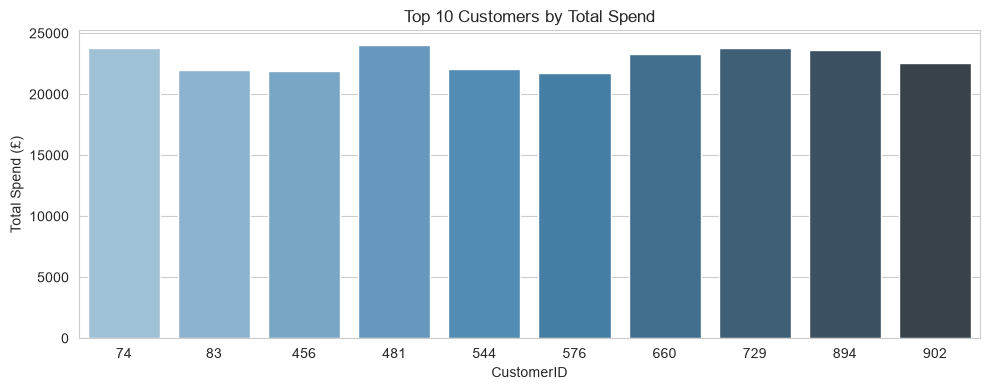

In [6]:
customer_spend = (tx_full.groupby('CustomerID')
    .agg(TotalSpend=('Spend','sum'),
         N_Transactions=('ProductID','count'),
         N_UniqueProducts=('ProductID','nunique'))
    .reset_index()
    .sort_values('TotalSpend', ascending=False))

print("=== TOP 10 CUSTOMERS BY SPEND ===")
top10_spend = customer_spend.head(10).merge(customers, on='CustomerID')
print(top10_spend[['CustomerID','TotalSpend','N_Transactions',
                   'N_UniqueProducts','LoyaltyLevel','Region','AgeGroup']])

fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(data=top10_spend, x='CustomerID', y='TotalSpend', ax=ax, palette='Blues_d')
ax.set_title('Top 10 Customers by Total Spend')
ax.set_xlabel('CustomerID'); ax.set_ylabel('Total Spend (£)')
plt.tight_layout(); plt.show()

=== TOP 10 CUSTOMERS BY PURCHASE FREQUENCY ===
   CustomerID  TotalPurchases  N_Transactions LoyaltyLevel Region
0         450              87              30       Bronze  South
1         880              87              31       Silver   West
2          74              86              30       Bronze  South
3         374              85              30       Bronze  South
4         811              85              31       Silver   West
5         168              84              31       Silver   West
6         329              83              27       Silver  North
7         298              82              29       Bronze   East
8         812              82              29       Bronze  South
9         240              81              29       Bronze   East


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\163834505.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_freq, x='CustomerID', y='TotalPurchases', ax=ax, palette='Greens_d')


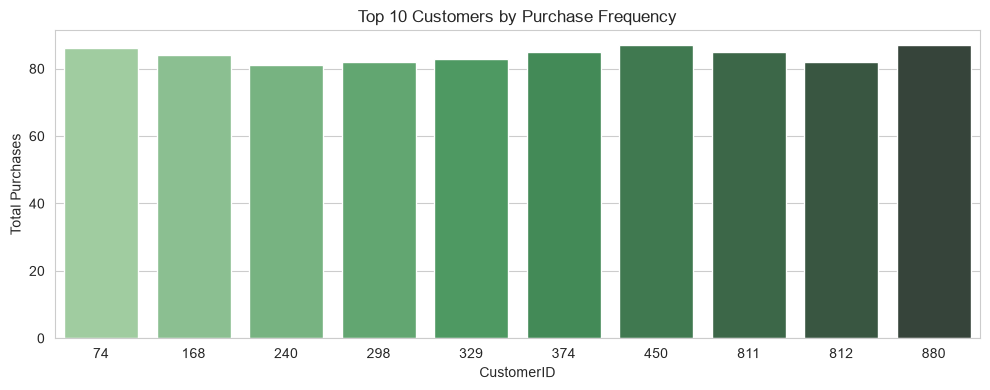

In [7]:
freq = (tx_full.groupby('CustomerID')
    .agg(TotalPurchases=('PurchaseCount','sum'),
         N_Transactions=('ProductID','count'))
    .reset_index()
    .sort_values('TotalPurchases', ascending=False))

print("=== TOP 10 CUSTOMERS BY PURCHASE FREQUENCY ===")
top10_freq = freq.head(10).merge(customers, on='CustomerID')
print(top10_freq[['CustomerID','TotalPurchases','N_Transactions','LoyaltyLevel','Region']])

fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(data=top10_freq, x='CustomerID', y='TotalPurchases', ax=ax, palette='Greens_d')
ax.set_title('Top 10 Customers by Purchase Frequency')
ax.set_xlabel('CustomerID'); ax.set_ylabel('Total Purchases')
plt.tight_layout(); plt.show()

=== CUSTOMER VALUE BY LOYALTY LEVEL ===
              N_Customers  AvgSpend  MedianSpend  TotalSpend  AvgTransactions
LoyaltyLevel                                                                 
Gold                  187  11477.92     11716.20  2146370.31            19.14
Silver                320  11404.52     11446.04  3649446.67            19.01
Bronze                493  11241.15     11326.61  5541886.64            18.59

Total revenue: £11,337,703.62
Top 10% of customers generate: 17.1% of revenue


C:\Users\Kiero\AppData\Local\Temp\ipykernel_24408\3134870020.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=loyalty_value.index, y=loyalty_value['AvgSpend'], ax=ax, palette='Oranges_d')


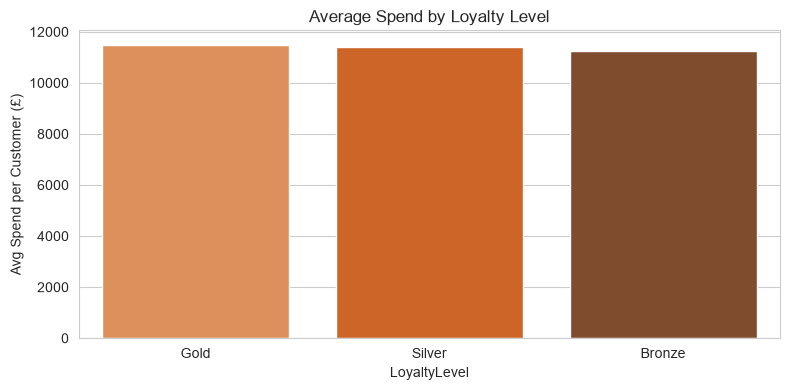

In [8]:
# Compute each customer's spend and merge loyalty tier
cv = customer_spend.merge(customers[['CustomerID','LoyaltyLevel']], on='CustomerID', how='left')

# Segment by LoyaltyLevel
loyalty_value = cv.groupby('LoyaltyLevel').agg(
    N_Customers=('CustomerID','count'),
    AvgSpend=('TotalSpend','mean'),
    MedianSpend=('TotalSpend','median'),
    TotalSpend=('TotalSpend','sum'),
    AvgTransactions=('N_Transactions','mean')
).round(2).sort_values('AvgSpend', ascending=False)

print("=== CUSTOMER VALUE BY LOYALTY LEVEL ===")
print(loyalty_value)
print(f"\nTotal revenue: £{cv['TotalSpend'].sum():,.2f}")
print(f"Top 10% of customers generate: "
      f"{cv.nlargest(max(1,int(len(cv)*0.1)), 'TotalSpend')['TotalSpend'].sum() / cv['TotalSpend'].sum():.1%} of revenue")

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=loyalty_value.index, y=loyalty_value['AvgSpend'], ax=ax, palette='Oranges_d')
ax.set_title('Average Spend by Loyalty Level')
ax.set_ylabel('Avg Spend per Customer (£)')
plt.tight_layout(); plt.show()